# Comparaison de M2 et du Classifier final

**M2** : Word TF-IDF + SVM linéaire, avec la recherche initiale et des seuils par quantiles.

**Classifier** :  Word TF-IDF + SVM linéaire, avec une recherche plus poussée et des seuils.

Les deux artefacts sont rechargés sans entraînement ni ajustement. La comparaison
porte sur toute la validation. Elle mesure l’effet global de la procédure.

## 1. Charger les modèles et la validation

Vérifier les empreintes de validation et l’ordre des huit cibles.
Les modèles, leurs représentations et leurs seuils sauvegardés restent inchangés.

In [29]:
import hashlib
import html
import json
import unicodedata
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, f1_score, hamming_loss, precision_recall_fscore_support,
)
from threadpoolctl import threadpool_limits

racine = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "data" / "validation.jsonl").is_file()), None)
if racine is None:
    raise FileNotFoundError("Ouvrez ce notebook depuis le dépôt du projet.")

contenu = (racine / "data" / "validation.jsonl").read_bytes()
empreinte_validation = hashlib.sha256(contenu).hexdigest()
validation = pd.DataFrame([json.loads(ligne) for ligne in
    contenu.decode("utf-8").splitlines() if ligne.strip()])
tags_cibles = ["math", "graphs", "strings", "number theory",
               "trees", "geometry", "games", "probabilities"]
colonnes_cibles = ["cible_" + tag.replace(" ", "_") for tag in tags_cibles]
assert len(validation) > 0 and validation[colonnes_cibles].isin([0, 1]).all().all()
assert validation["fichier_source"].is_unique
y_validation = validation[colonnes_cibles].to_numpy(dtype=np.int64)
exercices = validation.to_dict("records")

modeles = {
    "M2": joblib.load(racine / "models" / "m2_word_tfidf_linear_svm" / "modele.joblib"),
    "Classifier": joblib.load(racine / "classifier" / "resultats" / "modele.joblib"),
}
for nom, modele in modeles.items():
    assert [tag.replace("_", " ") for tag in modele["tags"]] == tags_cibles, nom
    assert modele["empreintes_donnees"]["validation"] == empreinte_validation, nom
    assert np.shape(modele["seuils"]) == (8,) and np.isfinite(modele["seuils"]).all(), nom
print(f"{len(validation)} exercices de validation, deux modèles sauvegardés.")

739 exercices de validation, deux modèles sauvegardés.


## 2. Comparer les performances globales

Comparer M2 et le classifier sur l’ensemble de validation à l’aide du F1 macro, du F1 micro, de l’Exact Match Ratio, de la Hamming Loss et du temps d’inférence médian par exercice.

In [30]:
def predire_exercice(exercice, modele):
    sections = []
    for champ, titre in modele["champs_texte"].items():
        valeur = exercice.get(champ)
        if isinstance(valeur, str):
            contenu = unicodedata.normalize("NFC", html.unescape(valeur)).strip()
            if contenu:
                sections.append(f"{titre}\n{contenu}")
    texte = "\n\n".join(sections)
    if not texte.strip():
        raise ValueError("L’énoncé doit contenir au moins une section textuelle non vide.")
    matrice = modele["vectoriseur"].transform([texte])
    scores = modele["classifieur"].decision_function(matrice)[0]
    assert np.shape(scores) == (8,) and np.isfinite(scores).all()
    return (scores >= np.asarray(modele["seuils"])).astype(np.int64)


lignes_globales = []
predictions_par_modele = {}
with threadpool_limits(limits=1):
    for nom, modele in modeles.items():
        for exercice in exercices[:3]:
            predire_exercice(exercice, modele)
        predictions, durees = [], []
        for exercice in exercices:
            debut = perf_counter()
            prediction = predire_exercice(exercice, modele)
            durees.append(1000 * (perf_counter() - debut))
            predictions.append(prediction)
        predictions = np.stack(predictions)
        assert predictions.shape == y_validation.shape and len(durees) == len(validation)
        predictions_par_modele[nom] = predictions
        lignes_globales.append({
            "Modèle": nom,
            "F1 macro": f1_score(y_validation, predictions, average="macro", zero_division=0),
            "F1 micro": f1_score(y_validation, predictions, average="micro", zero_division=0),
            "Exact Match Ratio": accuracy_score(y_validation, predictions),
            "Hamming Loss": hamming_loss(y_validation, predictions),
            "Inférence médiane (ms/exercice)": float(np.median(durees)),
        })
comparaison_globale = pd.DataFrame(lignes_globales)
display(comparaison_globale.round(4))

,Modèle,F1 macro,F1 micro,Exact Match Ratio,Hamming Loss,Inférence médiane (ms/exercice)
0,M2,0.6709,0.632,0.5643,0.0646,0.8080
1,Classifier,0.7121,0.654,0.5954,0.0585,0.6344


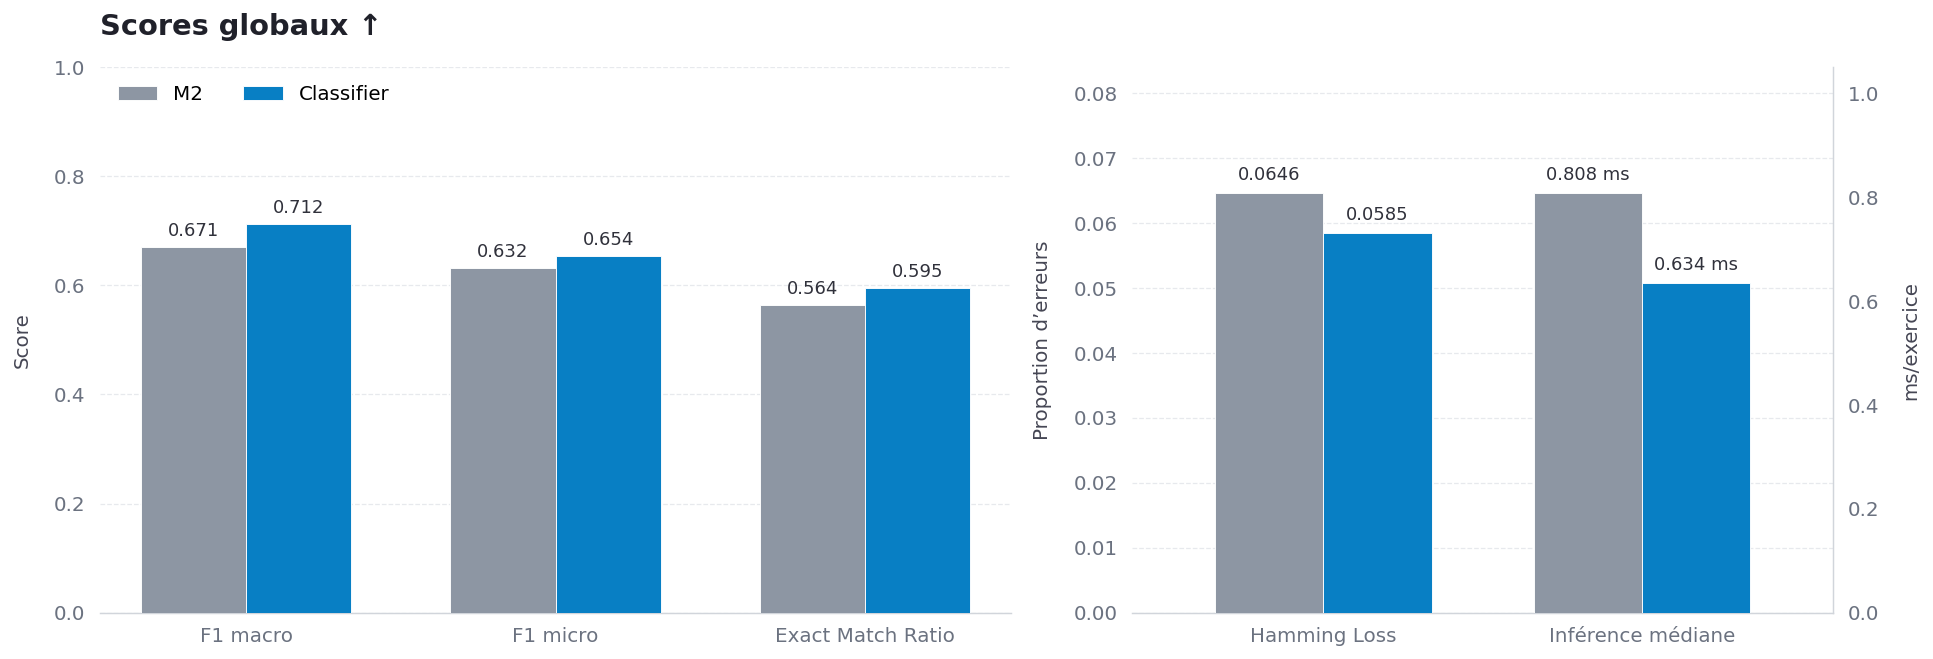

In [31]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
couleurs = {"M2": "#8D96A3", "Classifier": "#087FC4"}


def habiller_axe(axe, titre, direction_grille="y"):
    axe.set_title(titre, loc="left", pad=18, color="#20212A")
    axe.tick_params(axis="both", length=0, pad=8, colors="#6B7280")
    axe.set_axisbelow(True)
    axe.grid(axis=direction_grille, linestyle="--", linewidth=0.7,
             color="#E5E7EB", alpha=0.9)
    for cote in ["top", "right", "left"]:
        axe.spines[cote].set_visible(False)
    axe.spines["bottom"].set_color("#D1D5DB")
    axe.spines["bottom"].set_linewidth(0.8)


valeurs_globales = comparaison_globale.set_index("Modèle").loc[list(couleurs)]
figure, axes = plt.subplots(1, 2, figsize=(15, 5.2), dpi=130,
                            gridspec_kw={"width_ratios": [1.3, 1]})
metriques_scores = ["F1 macro", "F1 micro", "Exact Match Ratio"]
positions = np.arange(len(metriques_scores))
largeur = 0.34
for i, (nom, couleur) in enumerate(couleurs.items()):
    valeurs = valeurs_globales.loc[nom, metriques_scores].to_numpy(dtype=float)
    barres = axes[0].bar(positions + (i - 0.5) * largeur, valeurs,
                         width=largeur, color=couleur, edgecolor="white",
                         linewidth=0.5, label=nom, zorder=3)
    axes[0].bar_label(barres, labels=[f"{v:.3f}" for v in valeurs],
                      padding=4, fontsize=10, color="#30313B")
axes[0].set_xticks(positions, ["F1 macro", "F1 micro", "Exact Match Ratio"])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Score", labelpad=12, color="#454654")
habiller_axe(axes[0], "Scores globaux ↑")
axes[0].legend(frameon=False, loc="upper left", ncol=2)

axe_temps = axes[1].twinx()
for i, (nom, couleur) in enumerate(couleurs.items()):
    decalage = (i - 0.5) * largeur
    erreur = float(valeurs_globales.loc[nom, "Hamming Loss"])
    temps = float(valeurs_globales.loc[nom, "Inférence médiane (ms/exercice)"])
    barre_erreur = axes[1].bar(decalage, erreur, width=largeur,
        color=couleur, edgecolor="white", linewidth=0.5, zorder=3)
    barre_temps = axe_temps.bar(1 + decalage, temps, width=largeur,
        color=couleur, edgecolor="white", linewidth=0.5, zorder=3)
    axes[1].bar_label(barre_erreur, labels=[f"{erreur:.4f}"],
                      padding=5, fontsize=10, color="#30313B")
    axe_temps.bar_label(barre_temps, labels=[f"{temps:.3f} ms"],
                        padding=5, fontsize=10, color="#30313B")

axes[1].set_xlim(-0.6, 1.6)
axes[1].set_xticks([0, 1], ["Hamming Loss", "Inférence médiane"])
axes[1].set_ylim(0, valeurs_globales["Hamming Loss"].max() * 1.3)
axe_temps.set_ylim(0, valeurs_globales["Inférence médiane (ms/exercice)"].max() * 1.3)
axes[1].set_ylabel("Proportion d’erreurs", labelpad=12, color="#454654")
axe_temps.set_ylabel("ms/exercice", labelpad=12, color="#454654")
habiller_axe(axes[1], "")
axe_temps.tick_params(axis="y", length=0, pad=8, colors="#6B7280")
for cote in ["top", "left", "bottom"]:
    axe_temps.spines[cote].set_visible(False)
axe_temps.spines["right"].set_color("#D1D5DB")
axe_temps.spines["right"].set_linewidth(0.8)

figure.tight_layout()
plt.show()

## 3. Comparer les performances par tag

Comparer la précision, le rappel et le F1 de M2 et du classifier pour chacune des huit catégories, avec leur support et l’écart de F1 entre les deux modèles.

In [32]:
comparaison_tags = pd.DataFrame({
    "Tag": tags_cibles, "Support": y_validation.sum(axis=0),
})
for nom, predictions in predictions_par_modele.items():
    precisions, rappels, f1, _ = precision_recall_fscore_support(
        y_validation, predictions, average=None, zero_division=0)
    comparaison_tags[f"Précision {nom}"] = precisions
    comparaison_tags[f"Rappel {nom}"] = rappels
    comparaison_tags[f"F1 {nom}"] = f1
comparaison_tags["Écart F1"] = comparaison_tags["F1 Classifier"] - comparaison_tags["F1 M2"]
with pd.option_context("display.max_columns", None):
    display(comparaison_tags.round(4))

,Tag,Support,Précision M2,Rappel M2,F1 M2,Précision Classifier,Rappel Classifier,F1 Classifier,Écart F1
0,math,211,0.5570,0.6256,0.5893,0.5890,0.6114,0.6000,0.0107
1,graphs,81,0.6543,0.6543,0.6543,0.7313,0.6049,0.6622,0.0078
2,strings,63,0.6479,0.7302,0.6866,0.6667,0.7302,0.6970,0.0104
3,number theory,52,0.5893,0.6346,0.6111,0.6739,0.5962,0.6327,0.0215
4,trees,49,0.7838,0.5918,0.6744,0.7674,0.6735,0.7174,0.0430
5,geometry,25,0.6154,0.6400,0.6275,0.7391,0.6800,0.7083,0.0809
6,games,16,1.0000,0.7500,0.8571,1.0000,0.8125,0.8966,0.0394
7,probabilities,14,1.0000,0.5000,0.6667,1.0000,0.6429,0.7826,0.1159


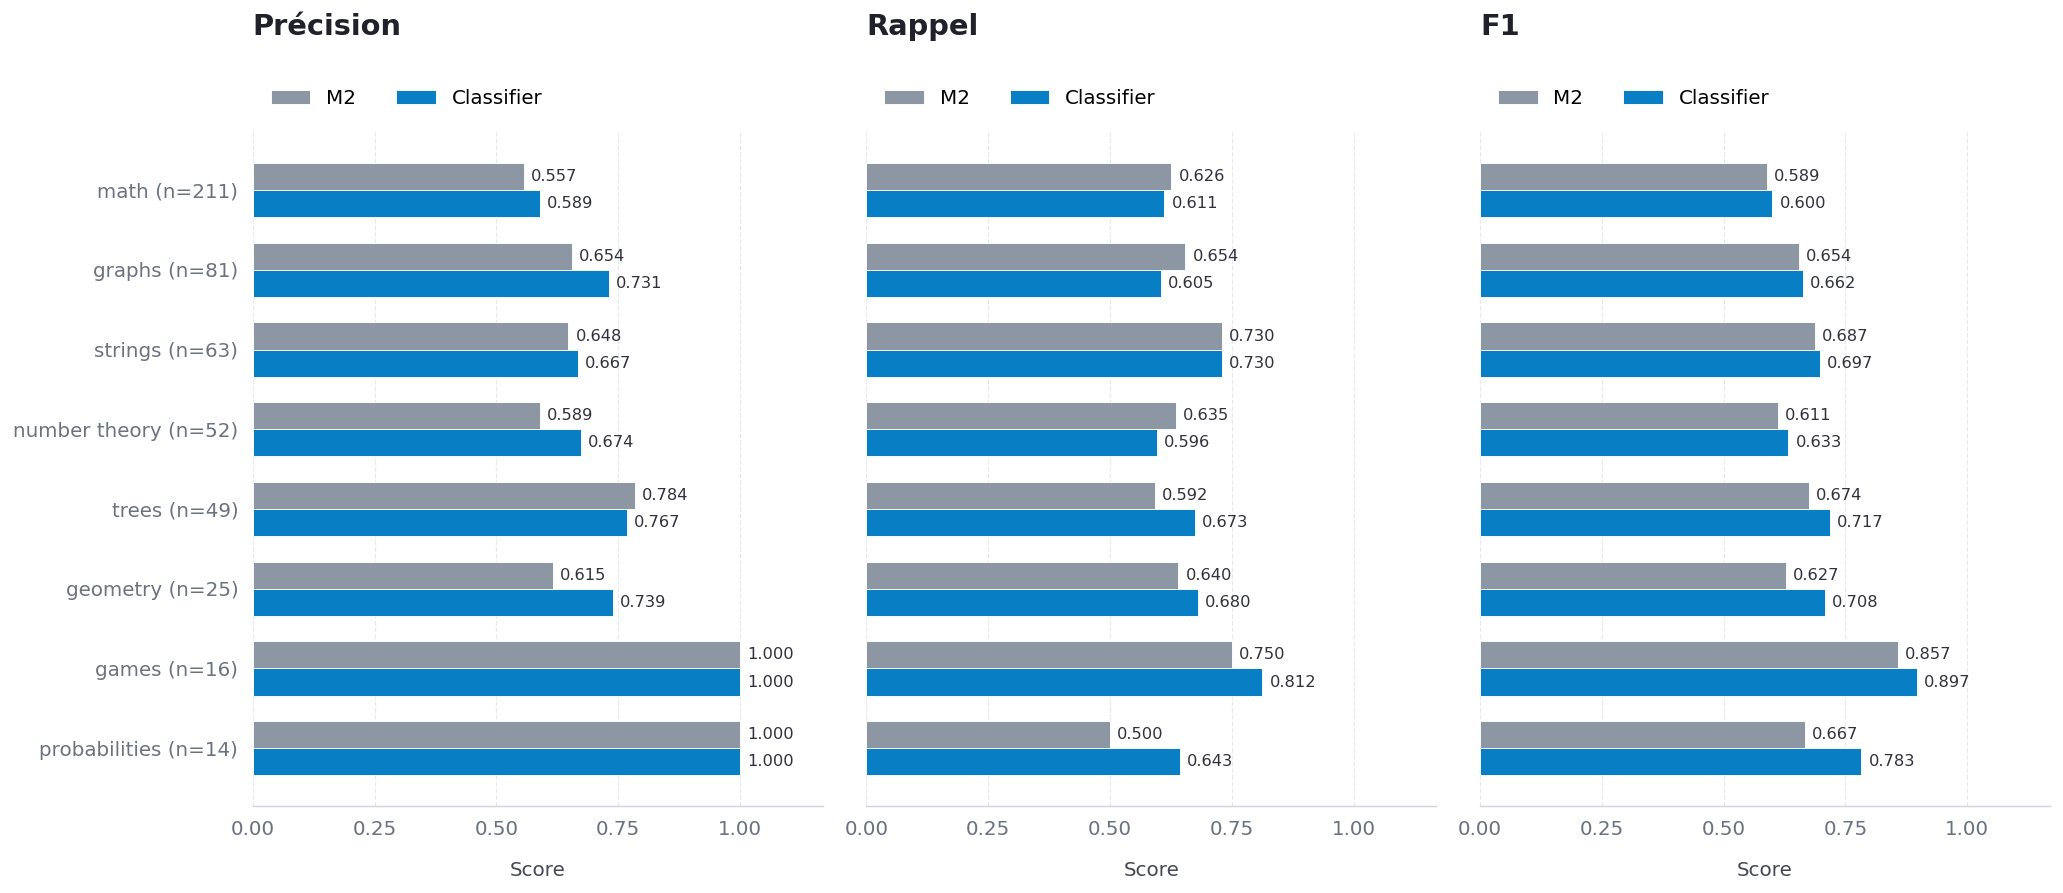

In [33]:
figure, axes = plt.subplots(1, 3, figsize=(16, 7), dpi=130, sharey=True)
positions = np.arange(len(comparaison_tags))
hauteur = 0.34
for axe, metrique in zip(axes, ["Précision", "Rappel", "F1"]):
    for i, (nom, couleur) in enumerate(couleurs.items()):
        valeurs = comparaison_tags[f"{metrique} {nom}"].to_numpy(dtype=float)
        barres = axe.barh(positions + (i - 0.5) * hauteur, valeurs,
                          height=hauteur, color=couleur, edgecolor="white",
                          linewidth=0.5, label=nom, zorder=3)
        axe.bar_label(barres, labels=[f"{v:.3f}" for v in valeurs],
                       padding=4, fontsize=9, color="#30313B")
    axe.set_xlim(0, 1.17) 
    axe.set_xticks([0, 0.25, 0.5, 0.75, 1])
    axe.set_xlabel("Score", labelpad=12, color="#454654")
    habiller_axe(axe, metrique, direction_grille="x")

axes[0].set_yticks(positions, [f"{tag} (n={support})" for tag, support
                              in comparaison_tags[["Tag", "Support"]].itertuples(index=False)])
axes[0].invert_yaxis()
for axe in axes:
    axe.set_title(axe.get_title(loc="left"), loc="left", pad=54, color="#20212A")
    axe.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False)
figure.tight_layout()
plt.show()